In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv("vendas_varejo_express.csv")

In [2]:
df

,ID_Pedido,Data_Pedido,Mes,Canal_Venda,Regiao,UF,Categoria,Forma_Pagamento,Valor_Bruto_R$,Desconto_R$,Frete_Cobrado_R$,Dias_Entrega,Prazo_Prometido,Nota_Cliente,Devolvido
0,PED-1001,2026-01-04,01-Jan,Site Web,Sudeste,SP,Eletrônicos,Cartão Crédito,789.9,40.0,15.9,3,5,5,Nao
1,PED-1002,2026-01-07,01-Jan,App Mobile,Sul,PR,Moda,Pix,142.5,0.0,12.0,4,6,5,Nao
2,PED-1003,2026-01-11,01-Jan,Marketplace,Nordeste,BA,Casa & Decoração,Cartão Crédito,310.0,15.0,24.5,8,9,4,Nao
3,PED-1004,2026-01-14,01-Jan,App Mobile,Sudeste,RJ,Esportes,Pix,229.9,20.0,14.0,5,5,4,Nao
4,PED-1005,2026-01-18,01-Jan,Site Web,Centro-Oeste,GO,Eletrônicos,Boleto,540.0,0.0,22.0,7,8,5,Nao
5,PED-1006,2026-01-21,01-Jan,App Mobile,Sudeste,MG,Moda,Cartão Crédito,118.0,10.0,11.5,4,5,5,Nao
6,PED-1007,2026-01-24,01-Jan,Marketplace,Norte,PA,Esportes,Pix,195.0,0.0,32.0,10,11,4,Nao
7,PED-1008,2026-01-27,01-Jan,Site Web,Sul,RS,Casa & Decoração,Cartão Crédito,415.0,35.0,18.0,5,6,5,Nao
8,PED-1009,2026-01-30,01-Jan,App Mobile,Nordeste,PE,Moda,Pix,98.9,0.0,19.9,9,9,3,Nao
9,PED-1010,2026-02-02,02-Fev,Site Web,Sudeste,SP,Eletrônicos,Cartão Crédito,1120.0,80.0,0.0,2,4,5,Nao


In [13]:
df["Valor_Liquido_brl"] = (df["Valor_Bruto_R$"] - df["Desconto_R$"])
df

,ID_Pedido,Data_Pedido,Mes,Canal_Venda,Regiao,UF,Categoria,Forma_Pagamento,Valor_Bruto_R$,Desconto_R$,Frete_Cobrado_R$,Dias_Entrega,Prazo_Prometido,Nota_Cliente,Devolvido,Valor_Liquido_brl
0,PED-1001,2026-01-04,01-Jan,Site Web,Sudeste,SP,Eletrônicos,Cartão Crédito,789.9,40.0,15.9,3,5,5,Nao,749.9
1,PED-1002,2026-01-07,01-Jan,App Mobile,Sul,PR,Moda,Pix,142.5,0.0,12.0,4,6,5,Nao,142.5
2,PED-1003,2026-01-11,01-Jan,Marketplace,Nordeste,BA,Casa & Decoração,Cartão Crédito,310.0,15.0,24.5,8,9,4,Nao,295.0
3,PED-1004,2026-01-14,01-Jan,App Mobile,Sudeste,RJ,Esportes,Pix,229.9,20.0,14.0,5,5,4,Nao,209.9
4,PED-1005,2026-01-18,01-Jan,Site Web,Centro-Oeste,GO,Eletrônicos,Boleto,540.0,0.0,22.0,7,8,5,Nao,540.0
5,PED-1006,2026-01-21,01-Jan,App Mobile,Sudeste,MG,Moda,Cartão Crédito,118.0,10.0,11.5,4,5,5,Nao,108.0
6,PED-1007,2026-01-24,01-Jan,Marketplace,Norte,PA,Esportes,Pix,195.0,0.0,32.0,10,11,4,Nao,195.0
7,PED-1008,2026-01-27,01-Jan,Site Web,Sul,RS,Casa & Decoração,Cartão Crédito,415.0,35.0,18.0,5,6,5,Nao,380.0
8,PED-1009,2026-01-30,01-Jan,App Mobile,Nordeste,PE,Moda,Pix,98.9,0.0,19.9,9,9,3,Nao,98.9
9,PED-1010,2026-02-02,02-Fev,Site Web,Sudeste,SP,Eletrônicos,Cartão Crédito,1120.0,80.0,0.0,2,4,5,Nao,1040.0


In [8]:
df.groupby(["Canal_Venda","Categoria", "Forma_Pagamento", "Nota_Cliente", "Devolvido"])[["Valor_Bruto_R$", "Desconto_R$"]].sum()

Valor_Bruto_R$  \
Canal_Venda Categoria        Forma_Pagamento Nota_Cliente Devolvido                   
App Mobile  Casa & Decoração Boleto          4            Nao                 230.0   
                             Cartão Crédito  1            Sim                 675.0   
                                             2            Nao                 320.0   
                             Pix             4            Nao                 345.0   
                                             5            Nao                 330.0   
            Eletrônicos      Cartão Crédito  1            Sim                 670.0   
                                             4            Nao                 890.0   
                                             5            Nao                3760.0   
                             Pix             1            Sim                 810.0   
                                             2            Nao                 760.0   
                                                          Sim                 680.0   
            Esportes         Cartão Crédito  2            Nao                 240.0   
                                             5            Nao                 310.0   
                             Pix             4            Nao                 434.9   
                                             5            Nao                 510.0   
            Moda             Cartão Crédito  1            Sim                 175.0   
                                             2            Sim                 185.0   
                                             5            Nao                 118.0   
                             Pix             3            Nao                 230.9   
                                             4            Nao                 283.0   
                                             5            Nao                 307.5   
Marketplace Casa & Decoração Cartão Crédito  4            Nao                 310.0   
            Eletrônicos      Boleto          1            Nao                 740.0   
                             Cartão Crédito  1            Sim                 920.0   
                                             4            Nao                 620.0   
                                             5            Nao                 880.0   
            Esportes         Pix             2            Sim                 260.0   
                                             4            Nao                 470.0   
            Moda             Cartão Crédito  1            Sim                 190.0   
                                             2            Nao                 160.0   
                                             3            Sim                  89.9   
                                             4            Nao                 178.0   
                                             5            Nao                 149.9   
                             Pix             3            Nao                 154.0   
                                             5            Nao                 115.0   
Site Web    Casa & Decoração Boleto          2            Nao                 310.0   
                             Cartão Crédito  3            Nao                 350.0   
                                             5            Nao                 805.0   
                             Pix             5            Nao                 685.0   
            Eletrônicos      Boleto          5            Nao                 540.0   
                             Cartão Crédito  4            Nao                 590.0   
                                             5            Nao                3564.9   
                             Pix             5            Nao                1050.0   
            Esportes         Boleto          5            Nao                 260.0   
            Moda             Cartão Crédito  5            Nao      

In [14]:
df.groupby(["Canal_Venda","Categoria"])[["Nota_Cliente", "Desconto_R$", "Valor_Liquido_brl"]].mean().round(2)

Nota_Cliente  Desconto_R$  Valor_Liquido_brl
Canal_Venda Categoria                                                     
App Mobile  Casa & Decoração          2.83        27.50             289.17
            Eletrônicos               3.12        91.25             855.00
            Esportes                  4.17        23.33             225.82
            Moda                      3.56        10.56             133.82
Marketplace Casa & Decoração          4.00        15.00             295.00
            Eletrônicos               2.75        71.25             718.75
            Esportes                  3.33        18.33             225.00
            Moda                      3.29        13.14             134.97
Site Web    Casa & Decoração          4.17        31.67             326.67
            Eletrônicos               4.86        51.43             769.27
            Esportes                  5.00         0.00             260.00
            Moda                      5.00        20.00             182.50

<Axes: xlabel='Categoria', ylabel='Valor_Liquido_brl'>

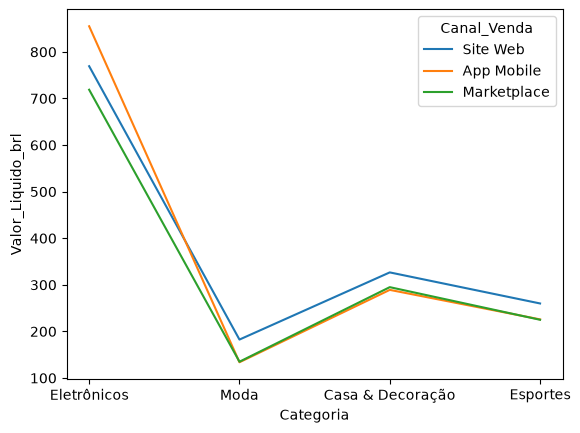

In [27]:
sns.lineplot(
    data = df,
    x ="Categoria",
    y = "Valor_Liquido_brl",
    hue = "Canal_Venda",
    errorbar = None
)

<Axes: xlabel='Regiao', ylabel='Valor_Liquido_brl'>

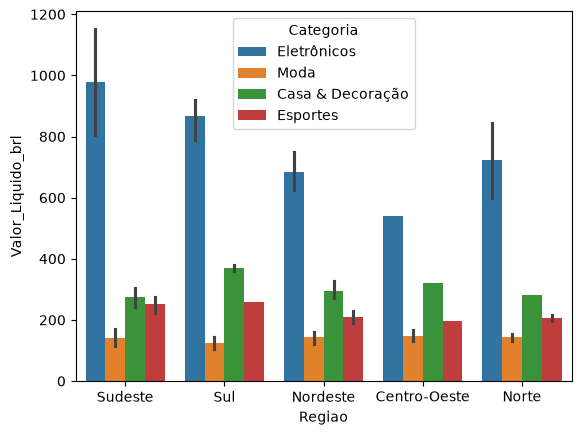

In [32]:
sns.barplot(
    data = df,
    x = "Regiao",
    y = "Valor_Liquido_brl",
    hue = "Categoria" 
)

In [34]:
df.groupby("Categoria")["Valor_Liquido_brl"].agg(["mean", "min", "max", "sum", "std"])

,mean,min,max,sum,std
Categoria,,,,,
Casa & Decoração,306.923077,230.0,380.0,3990.0,45.941016
Eletrônicos,794.731579,540.0,1300.0,15099.9,210.354547
Esportes,228.990000,190.0,280.0,2289.9,32.819048
Moda,139.677778,89.9,190.0,2514.2,27.571950


In [35]:
# 1. Calcula o ticket médio líquido por Canal e Categoria
previsao_base = df.groupby(['Canal_Venda', 'Categoria'])['Valor_Liquido_brl'].mean().reset_index()

# Renomeia a coluna para ficar mais claro
previsao_base.rename(columns={'Valor_Liquido_brl': 'Ticket_Medio'}, inplace=True)

print(previsao_base)


    Canal_Venda         Categoria  Ticket_Medio
0    App Mobile  Casa & Decoração    289.166667
1    App Mobile       Eletrônicos    855.000000
2    App Mobile          Esportes    225.816667
3    App Mobile              Moda    133.822222
4   Marketplace  Casa & Decoração    295.000000
5   Marketplace       Eletrônicos    718.750000
6   Marketplace          Esportes    225.000000
7   Marketplace              Moda    134.971429
8      Site Web  Casa & Decoração    326.666667
9      Site Web       Eletrônicos    769.271429
10     Site Web          Esportes    260.000000
11     Site Web              Moda    182.500000


C:\Users\senaij01\AppData\Local\Temp\ipykernel_18824\1741705030.py:5: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  previsao_base.rename(columns={'Valor_Liquido_brl': 'Ticket_Medio'}, inplace=True)


In [ ]:
# Define a quantidade estimada de vendas para cada linha
previsao_base['Pedidos_Estimados'] = 50 

# Calcula o faturamento previsto
previsao_base['Faturamento_Previsto'] = previsao_base['Ticket_Medio'] * previsao_base['Pedidos_Estimados']

# Exibe a tabela final e o total geral
print(previsao_base)
print(f"\nFaturamento Total Previsto: R$ {previsao_base['Faturamento_Previsto'].sum():,.2f}")


    Canal_Venda         Categoria  Ticket_Medio  Pedidos_Estimados  \
0    App Mobile  Casa & Decoração    289.166667                 50   
1    App Mobile       Eletrônicos    855.000000                 50   
2    App Mobile          Esportes    225.816667                 50   
3    App Mobile              Moda    133.822222                 50   
4   Marketplace  Casa & Decoração    295.000000                 50   
5   Marketplace       Eletrônicos    718.750000                 50   
6   Marketplace          Esportes    225.000000                 50   
7   Marketplace              Moda    134.971429                 50   
8      Site Web  Casa & Decoração    326.666667                 50   
9      Site Web       Eletrônicos    769.271429                 50   
10     Site Web          Esportes    260.000000                 50   
11     Site Web              Moda    182.500000                 50   

    Faturamento_Previsto  
0           14458.333333  
1           42750.000000  
2       

<Axes: xlabel='Categoria', ylabel='Faturamento_Previsto'>

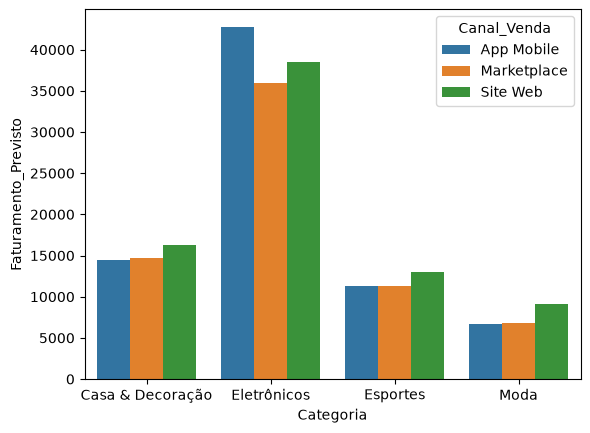

In [40]:
sns.barplot(
    data = previsao_base,
    y = "Faturamento_Previsto",
    x = "Categoria",
    hue = "Canal_Venda"
)

In [42]:
# 1. Garante que a coluna de data está no formato datetime
# Substitua 'Data_Venda' pelo nome real da sua coluna de datas
df['Data_Venda'] = pd.to_datetime(df['Data_Pedido'])

# 2. Cria uma coluna de Ano-Mês para agrupar os resultados
df['Mes'] = df['Data_Venda'].dt.to_period('M')

# 3. Soma o faturamento líquido por mês (ordenado cronologicamente)
faturamento_mensal = df.groupby('Mes')['Valor_Liquido_brl'].sum().reset_index()

# 4. Calcula a porcentagem de crescimento em relação ao mês anterior
faturamento_mensal['Crescimento_%'] = faturamento_mensal['Valor_Liquido_brl'].pct_change() * 100

# 5. Calcula a média de crescimento mensal de todo o período
crescimento_medio = faturamento_mensal['Crescimento_%'].mean()

# Exibe os resultados formatados
print(faturamento_mensal)
print(f"\nTaxa média de crescimento mensal: {crescimento_medio:.2f}%")


       Mes  Valor_Liquido_brl  Crescimento_%
0  2026-01             2719.2            NaN
1  2026-02             3549.9      30.549426
2  2026-03             3067.0     -13.603200
3  2026-04             3944.9      28.624063
4  2026-05             4853.0      23.019595
5  2026-06             5760.0      18.689470

Taxa média de crescimento mensal: 17.46%


In [43]:
ultimo_faturamento = faturamento_mensal['Valor_Liquido_brl'].iloc[-1]
previsao_proximo_mes = ultimo_faturamento * (1 + (crescimento_medio / 100))

print(f"Previsão para o próximo mês: R$ {previsao_proximo_mes:,.2f}")


Previsão para o próximo mês: R$ 6,765.46
